# Isolation Forest — reproducing the Shuttle experiment

**Paper:** F. T. Liu, K. M. Ting, Z.-H. Zhou, *Isolation Forest*, IEEE ICDM 2008, pp. 413–422.
**Reproduced:** Section 5.1, Table 3, **Shuttle** row — AUC and processing time of iForest, ORCA and LOF.

### What we are aiming at (Table 3, Shuttle row)

| Method | Paper's AUC | Paper's time (s) |
|---|---|---|
| iForest | 1.00 | 3.13 (training 0.30 + evaluation 2.83) |
| ORCA | 0.60 | 156.66 |
| LOF | 0.55 | 7489.74 |
| Random Forests | NA | NA |

Random Forests are NA in the paper's Shuttle row: the Table 3 caption says RF needs memory of order (2n)² for its proximity matrix. There is nothing to reproduce for RF.

### Where every choice comes from

Each setting is tagged with its source:

- **[paper]** — stated in the attached paper (section, algorithm, equation or table given);
- **[ref 3]** — taken from ORCA's own paper (Bay & Schwabacher, KDD 2003, reference [3] of the paper), used only for details of the ORCA baseline that the iForest paper does not give;
- **[ours]** — a decision the paper leaves open. These are few, all listed in Step 14, and where one could change a result its effect is measured.

### Order of the notebook

| Step | What happens |
|---|---|
| 0–3 | Settings, load the raw files and rebuild the dataset described in Table 2 |
| 4 | The anomaly score: Equations 1 and 2 |
| 5–7 | iForest from Algorithms 1, 2 and 3, checked on the Figure 1 example |
| 8–9 | iForest on Shuttle; cross-check with scikit-learn and with the one open implementation detail |
| 10–12 | ORCA, the paper's main baseline: build, validate, run |
| 13 | LOF |
| 14 | Every parameter used, then the comparison with Table 3 |
| 15 | Differences from the paper and their possible reasons |
| 16–17 | Supplementary (not in the paper for Shuttle): parameter sweeps and a per-class analysis |
| 18 | Save all measured numbers to JSON |

**Runtime:** about 15 minutes for the full run on one CPU thread (measured on the machine that produced the saved outputs; Step 0 explains the single thread). Most of it goes into the repeated ORCA runs of Step 12 and the large-`k` nearest-neighbour runs of Steps 16 and 17. The total is printed at the end. `FAST = True` in Step 0 gives a shorter run; what it leaves out is listed there.

---
## Step 0 — Requirements, settings and the paper's reference values

Only `numpy`, `scikit-learn` and `matplotlib` are needed (`threadpoolctl` comes with scikit-learn). All are pre-installed in Google Colab.

**One thread, CPU time.** Section 5 of the paper reports "actual CPU time" of experiments run "as single threaded jobs". NumPy's matrix products can use several CPU cores, which would speed up some methods (our ORCA) more than others and distort the timing comparison. `threadpool_limits(limits=1)` keeps every computation on one core, and all timings use `time.process_time()`, the CPU time of the process.

`FAST` trades completeness for speed:

| | `FAST = False` | `FAST = True` |
|---|---|---|
| Repeats per measurement (seeds) | 10 | 3 |
| psi, t and k sweeps (Step 16) | full grids | short grids, `k` stops at 500 |
| ORCA on raw (unscaled) attributes, sensitivity check | yes | skipped |
| `k = 5000` column in Step 17 | yes | skipped |

`FAST = True` still produces the three headline AUCs, from fewer seeds. The saved outputs and the report use `FAST = False`.

`PAPER` holds the only hand-typed numbers in the notebook: the Shuttle properties from the paper's Table 2 and the Shuttle row of its Table 3. Table 2 is used to rebuild the dataset (Step 3); Table 3 only for the comparison. Nothing is tuned to them.

In [1]:
import json, os, sys, time, math, platform, subprocess, collections
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import IsolationForest as SkIsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from threadpoolctl import threadpool_limits

# Section 5 of the paper: all experiments ran "as single threaded jobs" -> one core for everything
threadpool_limits(limits=1)

FAST = False       # True -> fewer repeats and shorter sweeps (see the table above)
N_RUNS = 3 if FAST else 10
NOTEBOOK_START = time.perf_counter()

# Reference values typed from the paper.
PAPER = dict(
    # Table 2, Shuttle row: dataset properties (used to rebuild the data in Step 3)
    n=49097, d=9, anomaly_classes=(2, 3, 5, 6, 7), anomaly_pct=7,
    # Table 3, Shuttle row: AUC (comparison only)
    iforest=1.00, orca=0.60, lof=0.55,
    # Table 3, Shuttle row: processing time in seconds (comparison only)
    if_train=0.30, if_eval=2.83, if_total=3.13, orca_s=156.66, lof_s=7489.74)

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("machine     ", platform.platform(), "|", platform.processor() or platform.machine())
print("\nFAST =", FAST, "| repeats per measurement:", N_RUNS, "| threads: 1")

python       3.14.5
numpy        2.5.4
scikit-learn 1.9.1
machine      macOS-26.7.1-arm64-arm-64bit-Mach-O | arm

FAST = False | repeats per measurement: 10 | threads: 1


---
## Step 1 — Getting the data files in

The paper's Shuttle data (its reference [2], the UCI repository) is the **UCI Statlog (Shuttle)** dataset. Two files are needed:

| File | What it is |
|---|---|
| `shuttle.trn.Z` | 43,500 training rows, compressed with the old Unix `compress` tool |
| `shuttle.tst` | 14,500 test rows, plain text |


In [2]:
TRN_Z = "shuttle.trn.Z"     
TST   = "shuttle.tst"
for p in (TRN_Z, TST):
    print(f"{p:16s} {'found' if os.path.exists(p) else 'NOT FOUND - check the path'}")

shuttle.trn.Z    found
shuttle.tst      found


---
## Step 2 — Decompressing `shuttle.trn.Z`

The `.Z` extension is Unix `compress` (LZW), **not** gzip, and Python's `gzip` module cannot read it. Two system tools can: `uncompress`, and `gzip -d`, which also understands the `.Z` format and is available on Linux, macOS and Colab. The function below tries them in that order and stops with a clear error if neither works.

If a plain-text `shuttle.trn` is already next to the notebook it is used instead, after checking that it has the 43,500 rows that `shuttle.doc` lists for the training file.

In [3]:
def decompress_Z(path_z, out_path, expected_rows=43500):   # 43,500 = training rows in shuttle.doc
    """Decompress a Unix .Z (LZW) file with the system tools. Returns out_path."""
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        rows = sum(1 for _ in open(out_path))
        assert rows == expected_rows, f"{out_path} has {rows} rows, expected {expected_rows}"
        print(f"{out_path} already present ({rows} rows), not decompressed again")
        return out_path
    for cmd in (["uncompress", "-c", path_z], ["gzip", "-dc", path_z]):
        try:
            with open(out_path, "wb") as fh:
                subprocess.run(cmd, stdout=fh, check=True, stderr=subprocess.DEVNULL)
            print(f"decompressed with `{cmd[0]}`")
            return out_path
        except (OSError, subprocess.CalledProcessError):
            if os.path.exists(out_path):
                os.remove(out_path)          # remove a partial file before trying the next tool
    raise RuntimeError(f"neither `uncompress` nor `gzip` could decompress {path_z}")

TRN = decompress_Z(TRN_Z, "shuttle.trn")

# peek: 9 numeric attributes then the class label in the last column
with open(TRN) as fh:
    for i, line in zip(range(3), fh):
        print(line.rstrip())
print("...")
print("rows in shuttle.trn:", sum(1 for _ in open(TRN)))
print("rows in shuttle.tst:", sum(1 for _ in open(TST)))

shuttle.trn already present (43500 rows), not decompressed again
50 21 77 0 28 0 27 48 22 2
55 0 92 0 0 26 36 92 56 4
53 0 82 0 52 -5 29 30 2 1
...
rows in shuttle.trn: 43500
rows in shuttle.tst: 14500


---
## Step 3 — Rebuilding the dataset the paper used

The raw files are a 7-class **classification** problem. The paper turns them into an **anomaly detection** problem but describes the result in one row of Table 2 only: *n = 49,097, d = 9, anomaly classes 2, 3, 5, 6, 7 (7 %)*. The rebuild follows that row:

1. **Pool the two files** (58,000 rows). `shuttle.doc` recommends a train/test split, but that is for classification; neither file alone has 49,097 rows, while the pooled data minus one whole class does (point 3). Pooling also fits our reading of the protocol: Section 5.1 says iForest "ranks all n points", and Section 5.4 introduces a train/evaluation split as a separate experiment, "so that the AUC is derived on unseen data". This suggests that in Section 5.1 all n points are used to build the model and all n are scored. The paper does not say so explicitly. *[ours, inferred]*
2. **Anomalies** are classes 2, 3, 5, 6, 7, as Table 2 says. *[paper]*
3. That leaves classes 1 and 4, and 58,000 − 49,097 = 8,903 rows must go. The code looks for a remaining class with exactly that many rows instead of assuming one, removes it, and keeps the other as **normal**. Exactly one class qualifies. *[ours, derived from Table 2]*

The `assert` lines check the result against every property in Table 2. If one fails, the input files differ from the paper's and no result below would be comparable.

In [5]:
full = np.vstack([np.loadtxt(TRN), np.loadtxt(TST)])
cls_all = full[:, -1].astype(int)
counts = collections.Counter(cls_all.tolist())
print("combined:", full.shape)
print("class counts:", dict(sorted(counts.items())))

# the class to drop is the one whose size equals the rows Table 2 does not account for
n_excess = len(full) - PAPER["n"]
others   = [c for c in counts if c not in PAPER["anomaly_classes"]]
dropped  = [c for c in others if counts[c] == n_excess]
assert len(dropped) == 1, "no single class explains the gap to Table 2's n"
REMOVED_CLASS = dropped[0]
print(f"\nrows to remove: {len(full)} - {PAPER['n']} = {n_excess} -> class {REMOVED_CLASS}; "
      f"normal class kept: {[c for c in others if c != REMOVED_CLASS]}")

keep = cls_all != REMOVED_CLASS
X    = full[keep, :-1].astype(np.float64)                     # the 9 attributes
cls  = cls_all[keep]                                         # original class, kept for Step 17
y    = np.isin(cls, PAPER["anomaly_classes"]).astype(int)    # 1 = anomaly, 0 = normal
ANOMALY_CLASSES = sorted(int(c) for c in np.unique(cls[y == 1]))

print(f"\nrebuilt:     n={X.shape[0]}  d={X.shape[1]}  anomalies={y.sum()} ({100*y.mean():.2f}%)"
      f"  classes {ANOMALY_CLASSES}")
print(f"paper Tab.2: n={PAPER['n']}  d={PAPER['d']}  anomaly classes "
      f"{list(PAPER['anomaly_classes'])} ({PAPER['anomaly_pct']}%)")
assert X.shape == (PAPER["n"], PAPER["d"]), "n or d does not match Table 2"
assert ANOMALY_CLASSES == sorted(PAPER["anomaly_classes"]), "anomaly classes do not match Table 2"
assert round(100 * y.mean()) == PAPER["anomaly_pct"], "anomaly share does not match Table 2"
print("\nmatches the paper's Table 2")

combined: (58000, 10)
class counts: {1: 45586, 2: 50, 3: 171, 4: 8903, 5: 3267, 6: 10, 7: 13}

rows to remove: 58000 - 49097 = 8903 -> class 4; normal class kept: [1]

rebuilt:     n=49097  d=9  anomalies=3511 (7.15%)  classes [2, 3, 5, 6, 7]
paper Tab.2: n=49097  d=9  anomaly classes [2, 3, 5, 6, 7] (7%)

matches the paper's Table 2


Two details that matter later. The anomalies are **not** one uniform group: four tiny classes and one large one. And the attributes have very different spreads, which matters for the two distance-based baselines (ORCA and LOF), not for iForest, whose splits look at one attribute at a time:

In [6]:
class_size = {c: int((cls == c).sum()) for c in ANOMALY_CLASSES}
LARGEST_CLASS = max(class_size, key=class_size.get)
print("anomaly classes:")
for c, size in class_size.items():
    print(f"  class {c}: {size:5d} rows  ({100*size/y.sum():5.1f}% of all anomalies)")
print(f"largest: class {LARGEST_CLASS}")

sd = X.std(axis=0)
var_share = sd**2 / (sd**2).sum()
print("\nattribute scales:")
for j in range(X.shape[1]):
    print(f"  attr {j}: min={X[:,j].min():9.1f}  max={X[:,j].max():9.1f}  sd={sd[j]:8.2f}"
          f"  share of total variance {100*var_share[j]:5.1f}%")
top2 = sorted(np.argsort(-var_share)[:2].tolist())
print(f"\n  largest sd / smallest sd = {sd.max()/sd.min():.1f}x;  attributes {top2} "
      f"carry {100*var_share[top2].sum():.0f}% of the total variance")

anomaly classes:
  class 2:    50 rows  (  1.4% of all anomalies)
  class 3:   171 rows  (  4.9% of all anomalies)
  class 5:  3267 rows  ( 93.1% of all anomalies)
  class 6:    10 rows  (  0.3% of all anomalies)
  class 7:    13 rows  (  0.4% of all anomalies)
largest: class 5

attribute scales:
  attr 0: min=     27.0  max=    126.0  sd=   12.88  share of total variance   0.3%
  attr 1: min=  -4821.0  max=   5075.0  sd=   84.67  share of total variance  12.3%
  attr 2: min=     21.0  max=    149.0  sd=    8.88  share of total variance   0.1%
  attr 3: min=  -3939.0  max=   3830.0  sd=   37.58  share of total variance   2.4%
  attr 4: min=   -188.0  max=    436.0  sd=   19.96  share of total variance   0.7%
  attr 5: min= -26739.0  max=  15164.0  sd=  218.32  share of total variance  82.1%
  attr 6: min=    -48.0  max=    105.0  sd=   13.45  share of total variance   0.3%
  attr 7: min=   -353.0  max=    270.0  sd=   20.57  share of total variance   0.7%
  attr 8: min=   -356.0  max= 

---
## Step 4 — The anomaly score (Equations 1 and 2)

Before building any trees we need the function that turns a path length into a score.

**The problem (Section 2).** A point's path length `h(x)` is the number of edges it travels from the root to the external node where it stops. Anomalies get short paths. Raw path lengths cannot be compared or bounded directly, though: the largest possible tree height grows like *n* and the average height like *log n*.

**The paper's solution.** An iTree has the same structure as a binary search tree (Table 1), and ending at an external node corresponds to an unsuccessful BST search. The average path length of an unsuccessful BST search is therefore used to normalise `h(x)` — **Equation 1**:

$$c(n) = 2H(n-1) - \frac{2(n-1)}{n}, \qquad H(i) \approx \ln(i) + 0.5772156649$$

**Equation 2** turns the average path length over the forest into a score:

$$s(x, n) = 2^{-E[h(x)] / c(n)}$$

The paper gives three limiting cases and how to read them:

| E[h(x)] | s | the paper's reading |
|---|---|---|
| → 0 | → 1 | instances with s very close to 1 are "definitely anomalies" |
| → c(n) | → 0.5 | if *all* instances have s ≈ 0.5, the sample has no distinct anomaly |
| → n − 1 | → 0 | instances whose s is well below 0.5 are "quite safe to be regarded as normal instances" |

The paper sets no fixed threshold for flagging a point (its Figure 3 example marks s ≥ 0.6 as potential anomalies). The evaluation uses AUC, which needs no threshold, so none is used here.

**Small n.** Equation 1 is defined with the harmonic number H; the paper offers ln(i) + 0.5772156649 as an *estimate* of it. The estimate fails for the smallest cases (it needs ln 0 at n = 1, and at n = 2 it gives c(2) = 0.15 instead of 1), so for n ≤ 2 the exact harmonic numbers are used: H(0) = 0 and H(1) = 1 give **c(1) = 0** and **c(2) = 1**, which is Equation 1 itself without the estimate. An empty external node (n = 0) can occur with Algorithm 2 as written (Step 5). Equation 1 is undefined there; **c(0) = 0** is used, since an empty node has no unbuilt subtree to correct for. *[ours, listed in Step 14]*

In [7]:
EULER = 0.5772156649          # Euler's constant as printed in the paper (Section 2)

def c_factor(n):
    """Equation 1: average path length of an unsuccessful BST search over n points.

    n > 2 : 2(ln(n-1) + 0.5772156649) - 2(n-1)/n   (the paper's estimate of H)
    n = 2 : 1    (exact harmonic number H(1) = 1)
    n <= 1: 0    (n = 1: H(0) = 0;  n = 0, an empty external node: our choice, see above)
    """
    n = np.asarray(n, dtype=np.float64)
    out = np.zeros_like(n)
    big = n > 2
    nb = n[big]
    out[big] = 2.0 * (np.log(nb - 1.0) + EULER) - 2.0 * (nb - 1.0) / nb
    out[n == 2] = 1.0
    return out


def score(mean_path, psi):
    """Equation 2 with n = psi (Section 4.2): s(x, psi) = 2^(-E[h(x)] / c(psi))."""
    return 2.0 ** (-np.asarray(mean_path, dtype=np.float64) / c_factor(np.array([psi]))[0])


for n_ in (256, 2, 1, 0):
    print(f"c({n_}) = {float(c_factor(np.array([n_]))[0]):.4f}")

# Equation 2 for psi = 256 at a few average path lengths, including the three limiting cases
c256 = float(c_factor(np.array([256]))[0])
print("\n  E[h(x)]       s")
for h in (0.0, 2.0, 5.0, c256, 15.0, 255.0):
    note = {0.0: "   E[h(x)] = 0           -> s = 1",
            c256: "   E[h(x)] = c(256)      -> s = 0.5",
            255.0: "   E[h(x)] = n - 1 = 255 -> s close to 0"}.get(h, "")
    print(f"  {h:7.2f}   {float(score(h, 256)):.4f}{note}")

c(256) = 10.2448
c(2) = 1.0000
c(1) = 0.0000
c(0) = 0.0000

  E[h(x)]       s
     0.00   1.0000   E[h(x)] = 0           -> s = 1
     2.00   0.8734
     5.00   0.7130
    10.24   0.5000   E[h(x)] = c(256)      -> s = 0.5
    15.00   0.3624
   255.00   0.0000   E[h(x)] = n - 1 = 255 -> s close to 0


---
## Step 5 — The isolation tree (Algorithm 2)

Growing one iTree, as Algorithm 2 states it:

> pick an attribute q at random from the attributes → pick a split value p at random between q's minimum and maximum **in the current node** → points with q < p go left, the rest go right → repeat on both sides.

**Stopping.** Algorithm 2 stops (i) at the height limit `l` or (ii) when |X| ≤ 1. The text of Section 2 adds (iii) "all data in X have the same values", which Algorithm 2 leaves out. Rule (iii) is applied as well: without it, identical points would only be split uselessly until the height limit.

**Why this isolates anomalies.** A point far from the rest sits in a wide empty region, so a random cut is likely to fall between it and everything else, and it is separated after a few splits. A point inside a dense region needs many cuts before it is alone.

**Attribute choice — implemented as written.** Algorithm 2 draws q from *all* attributes ("let Q be a list of attributes in X"). Inside a small node an attribute can be constant; then p equals that constant, no point satisfies q < p, and the left child is an empty external node (`Size = 0`). This is what the pseudocode does, so it is the default here (`attr_rule="all"`). The paper says only "randomly select" for both draws; they are taken to be uniform, the usual reading, which scikit-learn also uses. *[ours]* scikit-learn instead draws only among attributes that still vary in the node (verified in Step 9). That variant is kept as `attr_rule="varying"` and run once in Step 9 to measure whether this detail matters.

The tree is stored as flat NumPy arrays rather than linked objects, which makes scoring fast. `feature == -1` marks an external node.

In [8]:
class ITree:
    """One isolation tree: Algorithm 2 (building) and Algorithm 3 (path length)."""

    def __init__(self, X, height_limit, rng, attr_rule="all"):
        assert attr_rule in ("all", "varying")
        self.attr_rule = attr_rule
        self.feature, self.thresh = [], []      # split attribute q and split value p
        self.left, self.right, self.size = [], [], []
        self._build(X, 0, height_limit, rng)
        # freeze into arrays for fast traversal later
        self.feature = np.asarray(self.feature, dtype=np.int64)
        self.thresh  = np.asarray(self.thresh,  dtype=np.float64)
        self.left    = np.asarray(self.left,    dtype=np.int64)
        self.right   = np.asarray(self.right,   dtype=np.int64)
        self.size    = np.asarray(self.size,    dtype=np.float64)

    def _new_node(self):
        self.feature.append(-1); self.thresh.append(0.0)
        self.left.append(-1);    self.right.append(-1); self.size.append(0)
        return len(self.feature) - 1

    def _build(self, X, e, l, rng):
        """Algorithm 2. X = points in this node, e = current height, l = height limit."""
        node = self._new_node()
        n = X.shape[0]

        # Algorithm 2, line 1: height limit reached, or at most one point left
        if e >= l or n <= 1:
            self.size[node] = n                      # exNode{Size <- |X|}
            return node

        # Section 2, stopping rule (iii): all points in the node identical
        mins, maxs = X.min(axis=0), X.max(axis=0)
        varying = np.flatnonzero(maxs > mins)
        if varying.size == 0:
            self.size[node] = n
            return node

        # lines 4-5: random attribute q
        if self.attr_rule == "all":                  # as written: any of the d attributes
            q = int(rng.integers(X.shape[1]))
        else:                                        # scikit-learn's behaviour (Step 9)
            q = int(varying[rng.integers(varying.size)])
        # line 6: random split value p between the min and max of q in this node
        # (if q is constant here, p equals that constant and the left child is empty)
        p = rng.uniform(mins[q], maxs[q])

        go_left = X[:, q] < p                        # lines 7-8: filter on q < p
        self.feature[node] = q
        self.thresh[node]  = p
        self.left[node]  = self._build(X[go_left],  e + 1, l, rng)
        self.right[node] = self._build(X[~go_left], e + 1, l, rng)
        return node

    def path_length(self, X):
        """Algorithm 3, vectorised: every point moves down one level per pass.

        Returns e + c(T.size) at the external node where each point stops: e is the number of
        edges travelled, c(T.size) corrects for the subtree that was not built because of the
        height limit (Section 4.2).
        """
        n = X.shape[0]
        idx   = np.zeros(n, dtype=np.int64)      # current node of each point, starts at root
        depth = np.zeros(n, dtype=np.float64)    # edges travelled so far
        rows  = np.arange(n)
        while True:
            f = self.feature[idx]
            active = f >= 0                      # still at an internal node
            if not active.any():
                break
            go_left = X[rows, np.where(active, f, 0)] < self.thresh[idx]
            nxt = np.where(go_left, self.left[idx], self.right[idx])
            idx = np.where(active, nxt, idx)     # points already at a leaf stay put
            depth += active                      # and stop accumulating depth
        return depth + c_factor(self.size[idx])

print("ITree defined")

ITree defined


---
## Step 6 — The forest (Algorithm 1)

A single random tree is noisy, so iForest averages path lengths over `t` trees. Two design choices keep this cheap:

**Sub-sampling** (Section 3, Algorithm 1). Each tree is grown from a fresh sample of `psi` points drawn **without replacement**, not from all 49,097. The paper's default is `psi = 256` (Section 4.1). Section 3 argues that small samples are *better*, not just cheaper, because they reduce swamping and masking; Step 16 tests this on Shuttle.

**The height limit** (Section 4.1). `l = ceiling(log2 psi)`, about the average height of a tree on `psi` points. Only points with shorter-than-average paths are of interest, so the deeper part of each tree is never built: every tree is a deliberately **partial model**. A point that stops at a leaf still holding `Size` points gets the correction `c(Size)` (Algorithm 3).

With `psi = 256` this gives `l = 8`. A tree of height 8 has at most 2⁹ − 1 = 511 nodes, the figure Section 6 uses for its memory estimate; the cell below checks it on Shuttle.

The score of a point is Equation 2 with n = psi, `s(x, psi)`, as Section 4.2 specifies.

In [9]:
class IsolationForest:
    """Algorithm 1 (training) and Section 4.2 (evaluation)."""

    def __init__(self, n_trees=100, subsample=256, seed=0, attr_rule="all"):
        self.t    = n_trees      # number of trees t
        self.psi  = subsample    # sub-sampling size psi
        self.seed = seed
        self.attr_rule = attr_rule

    def fit(self, X):
        rng  = np.random.default_rng(self.seed)
        X    = np.asarray(X, dtype=np.float64)
        n    = X.shape[0]
        self.psi_ = min(self.psi, n)          # guard for tiny data; never triggered in this notebook
        self.l_   = int(math.ceil(math.log2(self.psi_)))                 # line 2: height limit
        self.trees_ = []
        for _ in range(self.t):                                           # lines 3-6
            sub = rng.choice(n, size=self.psi_, replace=False)            # without replacement
            self.trees_.append(ITree(X[sub], self.l_, rng, self.attr_rule))
        return self

    def mean_path_length(self, X):
        """E[h(x)]: Algorithm 3 averaged over the forest."""
        X = np.asarray(X, dtype=np.float64)
        return sum(tr.path_length(X) for tr in self.trees_) / len(self.trees_)

    def score_samples(self, X):
        """Equation 2 with n = psi. Higher score = more anomalous."""
        return score(self.mean_path_length(X), self.psi_)

probe = IsolationForest(n_trees=100, subsample=256, seed=0).fit(X)
print("IsolationForest defined")
print(f"psi = 256 -> height limit l = {probe.l_}; largest of 100 trees grown on Shuttle: "
      f"{max(len(tr.feature) for tr in probe.trees_)} nodes (bound 2^(l+1) - 1 = {2**(probe.l_ + 1) - 1})")

IsolationForest defined
psi = 256 -> height limit l = 8; largest of 100 trees grown on Shuttle: 239 nodes (bound 2^(l+1) - 1 = 511)


---
## Step 7 — Does it work? (the Figure 1 example)

Before running on 49,097 rows, check the core claim on data where the answer is known. Figure 1 of the paper takes 135 points from a Gaussian distribution, picks a normal point `xi` and an anomaly `xo`, and isolates each one by random partitioning: averaged over 1,000 trees, `xi` needs 12.82 partitions and `xo` 4.02.

Figure 1 counts partitions until a point is **completely isolated**, so here the trees are grown without an effective height limit (`l = n − 1`, which is never reached) and on all 135 points, without sub-sampling. The paper does not publish its 135 points. Ours are drawn from a standard 2-D Gaussian, and the two test points are chosen from the sample by a rule, not placed by hand: `xi` is the point nearest the sample mean, `xo` the point farthest from it. The numbers therefore cannot match the paper's exactly; what should match is the pattern, `xo` needing far fewer partitions than `xi`.

In [10]:
demo = np.random.default_rng(42).standard_normal((135, 2))     # 135 points, as in Figure 1
dist_to_mean = np.linalg.norm(demo - demo.mean(axis=0), axis=1)
i_xi, i_xo = int(np.argmin(dist_to_mean)), int(np.argmax(dist_to_mean))

rng_demo = np.random.default_rng(0)
no_limit = len(demo) - 1                     # height limit never reached: grow until isolated
paths = np.mean([ITree(demo, no_limit, rng_demo).path_length(demo) for _ in range(1000)], axis=0)

rank_xo = 1 + int((paths < paths[i_xo]).sum())
print(f"  xi, the point nearest the mean  : {paths[i_xi]:5.2f} partitions on average")
print(f"  xo, the point farthest from mean: {paths[i_xo]:5.2f} partitions on average")
print(f"  ratio xi / xo = {paths[i_xi] / paths[i_xo]:.1f};  xo's rank among all 135 points by path length: "
      f"{rank_xo} (1 = shortest)")
print("\npaper, Figure 1(c), 1000 trees, on its own sample: xi 12.82, xo 4.02 (ratio 3.2)")

  xi, the point nearest the mean  : 11.97 partitions on average
  xo, the point farthest from mean:  3.67 partitions on average
  ratio xi / xo = 3.3;  xo's rank among all 135 points by path length: 1 (1 = shortest)

paper, Figure 1(c), 1000 trees, on its own sample: xi 12.82, xo 4.02 (ratio 3.2)


---
## Step 8 — Running iForest on Shuttle

The paper's defaults: `t = 100`, `psi = 256` (Section 4.1).

Protocol, as in Section 5.1:

- **All n points are used to build the model, and all n are scored** (our reading of Sections 5.1 and 5.4; Step 3). This is unsupervised anomaly detection: the labels are never shown to the algorithm, so there is nothing to overfit to.
- **Labels are used for one thing only, AUC.** Section 5: "Anomaly labels are only available in the evaluation stage to compute the performance measure, AUC." AUC is the probability that a randomly chosen anomaly scores higher than a randomly chosen normal point: 1.0 is a perfect ranking, 0.5 is random.

The trees are random, so the run is repeated with `N_RUNS` seeds. The paper prints single values with no repetition count or variance, so we measure the spread ourselves. Times are CPU times on one thread, as in Section 5: training = building the forest, evaluation = scoring all n points, the split used in Table 3.

In [11]:
T, PSI = 100, 256                    # [paper] Section 4.1 defaults

aucs, t_train, t_eval = [], [], []
for seed in range(N_RUNS):
    model = IsolationForest(n_trees=T, subsample=PSI, seed=seed)
    t0 = time.process_time(); model.fit(X)                    # CPU time, as in Section 5
    t1 = time.process_time(); scores_if = model.score_samples(X)
    t2 = time.process_time()
    aucs.append(roc_auc_score(y, scores_if))
    t_train.append(t1 - t0); t_eval.append(t2 - t1)

aucs = np.array(aucs)
iforest_auc, iforest_sd = aucs.mean(), aucs.std(ddof=1)
iforest_train, iforest_eval = np.mean(t_train), np.mean(t_eval)

print(f"iForest over {N_RUNS} seeds")
print(f"  AUC      {iforest_auc:.4f} +/- {iforest_sd:.4f}   (min {aucs.min():.4f}, max {aucs.max():.4f})")
print(f"  training {iforest_train:.3f} s CPU")
print(f"  scoring  {iforest_eval:.3f} s CPU")
print(f"  total    {iforest_train + iforest_eval:.3f} s CPU")
print(f"\n  paper: AUC {PAPER['iforest']:.2f}, train {PAPER['if_train']:.2f} s, "
      f"eval {PAPER['if_eval']:.2f} s, total {PAPER['if_total']:.2f} s")
print(f"  -> our {iforest_auc:.4f} rounds to {iforest_auc:.2f}")

iForest over 10 seeds
  AUC      0.9969 +/- 0.0006   (min 0.9962, max 0.9976)
  training 0.034 s CPU
  scoring  0.285 s CPU
  total    0.319 s CPU

  paper: AUC 1.00, train 0.30 s, eval 2.83 s, total 3.13 s
  -> our 0.9969 rounds to 1.00


---
## Step 9 — Cross-check with scikit-learn, and the one open implementation detail

`sklearn.ensemble.IsolationForest` is an independent implementation of the same paper. Running it with the same `t` and `psi` checks our code: if the two agree, ours is unlikely to be wrong in a way that matters. (scikit-learn returns the score with the opposite sign, hence the minus.)

scikit-learn departs from Algorithm 2 in one detail: it never splits on an attribute that is constant in the node, so it never creates an empty child. The cell counts empty children in its fitted trees and in ours, then runs our forest with scikit-learn's rule (`attr_rule="varying"`) to measure whether this detail changes the result.

In [12]:
sk_aucs = []
for seed in range(N_RUNS):
    sk = SkIsolationForest(n_estimators=T, max_samples=PSI, random_state=seed).fit(X)
    sk_aucs.append(roc_auc_score(y, -sk.score_samples(X)))     # note the sign flip
    if seed == 0:
        sk_first = sk
sk_auc, sk_sd = float(np.mean(sk_aucs)), float(np.std(sk_aucs, ddof=1))

# empty children: scikit-learn (seed 0) versus our Algorithm 2 as written (seed 0)
sk_splits = sk_empty = 0
for est in sk_first.estimators_:
    tr = est.tree_
    for node in np.flatnonzero(tr.children_left >= 0):
        sk_splits += 1
        sk_empty += int(min(tr.n_node_samples[tr.children_left[node]],
                            tr.n_node_samples[tr.children_right[node]]) == 0)
ours0 = IsolationForest(T, PSI, seed=0).fit(X)
our_splits = sum(int((tr.feature >= 0).sum()) for tr in ours0.trees_)
our_empty  = sum(int(((tr.feature < 0) & (tr.size == 0)).sum()) for tr in ours0.trees_)
print(f"splits with an empty child: scikit-learn {sk_empty} of {sk_splits}; "
      f"ours (Algorithm 2 as written) {our_empty} of {our_splits} ({100*our_empty/our_splits:.0f}%)")

var_aucs = np.array([roc_auc_score(y, IsolationForest(T, PSI, seed=s, attr_rule="varying").fit(X).score_samples(X))
                     for s in range(N_RUNS)])
var_auc, var_sd = float(var_aucs.mean()), float(var_aucs.std(ddof=1))

print(f"\nours, Algorithm 2 as written ('all')    {iforest_auc:.4f} +/- {iforest_sd:.4f}")
print(f"ours, scikit-learn's rule ('varying')   {var_auc:.4f} +/- {var_sd:.4f}")
print(f"scikit-learn                            {sk_auc:.4f} +/- {sk_sd:.4f}")
print(f"\nsame rule, two implementations: |ours 'varying' - scikit-learn| = {abs(var_auc - sk_auc):.4f}")
print(f"effect of the open detail:      |'all' - 'varying'|              = {abs(iforest_auc - var_auc):.4f}")
print(f"largest seed-to-seed sd among the three: {max(iforest_sd, var_sd, sk_sd):.4f}")

splits with an empty child: scikit-learn 0 of 5200; ours (Algorithm 2 as written) 669 of 5322 (13%)

ours, Algorithm 2 as written ('all')    0.9969 +/- 0.0006
ours, scikit-learn's rule ('varying')   0.9971 +/- 0.0009
scikit-learn                            0.9970 +/- 0.0005

same rule, two implementations: |ours 'varying' - scikit-learn| = 0.0001
effect of the open detail:      |'all' - 'varying'|              = 0.0002
largest seed-to-seed sd among the three: 0.0009


---
## Step 10 — ORCA, the paper's main baseline

ORCA (Bay & Schwabacher, KDD 2003, reference [3] of the paper) is the method iForest is mainly compared with. The iForest paper gives its settings (`k = 5`, `N = n/8`, Section 5) and says it uses "sample randomisation together with a simple pruning rule", but not how ORCA scores or preprocesses the data. Those details, and only those, are taken from ORCA's own paper *[ref 3]*:

- **Score:** "the average distance to the nearest k neighbors" (ref 3, Section 3). Points in a crowd have close neighbours and score low; isolated points score high. Computing it exactly compares every pair of points, about 2.4 billion distances here.
- **Preprocessing:** ref 3 normalises "all continuous variables to the range [0,1]" before computing Euclidean distances. The iForest paper only says that the time of ORCA's pre-processing step, `dprep`, is left out of the timings. [0,1] scaling is therefore used as ORCA's preprocessing, and raw (unscaled) attributes are run as a sensitivity check.
- **Block size:** 1,000 examples, as in ref 3's experiments.

**How ORCA gets fast.**

1. **Randomisation.** Ref 3 assumes the examples are in random order. A normal point then meets close neighbours after only a few comparisons, so it can be dropped early by the pruning rule below; if the data were sorted, this could take much longer (ref 3, Sections 4 and 6).
2. **Pruning.** ORCA wants only the top `N` outliers. The *cutoff* is the score of the weakest of the current top `N`; it starts at zero and rises as more extreme outliers are found. As a candidate is compared with more and more points, its running score can only **go down** (a closer neighbour lowers the average, nothing can raise it). Once it falls below the cutoff, the candidate can never reach the top `N` and is dropped. ORCA checks this after every comparison; this implementation checks after each block of 1,000 comparisons, so it prunes slightly later (more work), but which points end up in the top `N` cannot change.

**ORCA's output and the AUC.** ORCA reports only the top `N` outliers with their scores. AUC needs a score for every point, and the paper connects the two: "it would be unreasonable to set N below the number of anomalies due to AUC's requirement to report anomaly scores for every instances". This is consistent with the unreported points being ranked, tied, below the `N` reported ones, and that is how ORCA's output is scored here (**top-N output**). The paper does not state it explicitly. *[ours, listed in Step 14]*

As a reference, the exact k-NN score of every point is also computed. It is what ORCA would output with `N = n`, when nothing can be pruned.

In [13]:
import heapq

def scale01(A):
    """[0,1] scaling of every attribute, ORCA's preprocessing in ref 3 (Section 3)."""
    A = np.asarray(A, dtype=np.float64)
    lo, hi = A.min(axis=0), A.max(axis=0)
    return (A - lo) / np.where(hi > lo, hi - lo, 1.0)


def exact_knn_score(A, k=5, chunk=2000):
    """Average distance to the k nearest neighbours, exact, for every point.

    ORCA's score with nothing pruned. Used to validate the ORCA implementation (Step 11) and as
    the 'no approximation' reference.
    """
    A = np.asarray(A, dtype=np.float64)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(A)
    out = np.empty(A.shape[0])
    for s in range(0, A.shape[0], chunk):
        dist, _ = nn.kneighbors(A[s:s + chunk])
        out[s:s + chunk] = dist[:, 1:].mean(axis=1)    # column 0: the point itself (distance 0)
    return out


def orca(A, k=5, N=None, block=1000, seed=0):
    """ORCA: randomised scan with cutoff pruning (ref 3).

    Returns (scores, info). Scores are exact for points that survive the scan and an upper bound
    for pruned points; the N largest are ORCA's top-N output (see top_n_only).
    """
    A = np.asarray(A, dtype=np.float64)
    n = A.shape[0]
    if N is None:
        N = max(1, n // 8)
    rng   = np.random.default_rng(seed)
    order = rng.permutation(n)            # trick 1: randomisation
    As    = A[order]
    sq    = (As ** 2).sum(axis=1)         # precomputed for the distance identity below

    scores   = np.zeros(n)
    topN     = []        # min-heap holding the N best scores seen so far
    cutoff   = 0.0       # the weakest of those N
    pruned   = 0
    dist_done = 0

    for start in range(0, n, block):
        stop = min(start + block, n)
        cand = np.arange(start, stop)
        knn   = np.full((cand.size, k), np.inf)      # k smallest squared distances so far
        alive = np.ones(cand.size, dtype=bool)       # still worth scanning?

        for rs in range(0, n, block):
            re  = min(rs + block, n)
            idx = np.flatnonzero(alive)
            if idx.size == 0:
                break                                 # whole block pruned, stop early

            # ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b  -> one matrix product per block pair
            D = (sq[cand[idx]][:, None] + sq[rs:re][None, :]
                 - 2.0 * As[cand[idx]] @ As[rs:re].T)
            np.maximum(D, 0.0, out=D)                 # clip tiny negatives from rounding
            D[cand[idx][:, None] == np.arange(rs, re)[None, :]] = np.inf   # not its own neighbour
            dist_done += D.size

            merged = np.concatenate([knn[idx], D], axis=1)
            # only the k smallest matter and their order inside the row is irrelevant
            # (the score is their mean), so partition instead of a full sort
            knn[idx] = np.partition(merged, k - 1, axis=1)[:, :k]

            # trick 2: pruning. The running score only ever decreases.
            running = np.sqrt(knn[idx]).mean(axis=1)
            drop = idx[running < cutoff]
            if drop.size:
                alive[drop] = False
                pruned += drop.size

        final = np.sqrt(knn).mean(axis=1)
        scores[order[cand]] = final                   # map back to the original row order

        for j in np.flatnonzero(alive):               # refresh the top N and the cutoff
            if len(topN) < N:
                heapq.heappush(topN, final[j])
            elif final[j] > topN[0]:
                heapq.heapreplace(topN, final[j])
        cutoff = topN[0] if len(topN) == N else 0.0

    return scores, dict(k=k, N=int(N), pruned=int(pruned),
                        distances_computed=int(dist_done),
                        distances_bruteforce=int(n) * int(n))


def top_n_only(scores, N):
    """ORCA's output as used for AUC: the N reported points keep their scores, all others tie below.

    A pruned point's upper bound was below the cutoff when it was pruned, and the cutoff only
    rises, so the N largest entries of orca()'s scores are exactly ORCA's top N.
    """
    out = np.full(scores.shape, scores.min() - 1.0)
    top = np.argsort(-scores)[:N]
    out[top] = scores[top]
    return out

print("ORCA defined")

ORCA defined


---
## Step 11 — Validating ORCA

Same idea as Step 7: check the implementation on small data where the answer is known.

1. **No pruning.** With `N = n` the cutoff can never be used, nothing is pruned, and the scores must equal the exact k-NN computation. Agreement to about 1e-15 shows the distance arithmetic and bookkeeping are right.
2. **With pruning.** With `N = n/8`, pruning must save work **without changing the answer**: ORCA's top `N` must be exactly the top `N` of the exact scores.

In [16]:
rng_v = np.random.default_rng(0)
Xv = rng_v.standard_normal((800, 4))
# three planted anomalies, far apart so that none of them is a neighbour of another
Xv[0] += 8; Xv[1] -= 8; Xv[2, 0] += 10

exact_v = exact_knn_score(Xv, k=5)
orca_v, _ = orca(Xv, k=5, N=800, block=200)            # N = n -> no pruning possible
print(f"1. max |exact - ORCA without pruning| = {np.abs(exact_v - orca_v).max():.2e}   (should be ~1e-15)")
print(f"   the 3 planted anomalies are the exact top 3: {set(np.argsort(-exact_v)[:3].tolist()) == {0, 1, 2}}")

Nv = 800 // 8
orca_p, info_v = orca(Xv, k=5, N=Nv, block=200)        # N = n/8 -> pruning on
same_top = set(np.argsort(-orca_p)[:Nv].tolist()) == set(np.argsort(-exact_v)[:Nv].tolist())
print(f"\n2. N = n/8: pruned {info_v['pruned']} of 800 candidates, computed "
      f"{100*info_v['distances_computed']/info_v['distances_bruteforce']:.0f}% of the brute-force distances")
print(f"   ORCA's top {Nv} identical to the exact top {Nv}: {same_top}")

1. max |exact - ORCA without pruning| = 2.44e-15   (should be ~1e-15)
   the 3 planted anomalies are the exact top 3: True

2. N = n/8: pruned 429 of 800 candidates, computed 72% of the brute-force distances
   ORCA's top 100 identical to the exact top 100: True


---
## Step 12 — Running ORCA on Shuttle (Cell takes a little bit time run it !)

The paper's settings: `k = 5`, `N = n/8` (Section 5). Input: attributes scaled to [0,1], ORCA's preprocessing (Step 10); raw attributes as a sensitivity check in the full run.

Which points form the top `N` does not depend on the scan order (Step 11), so the top-N AUC is the same for every seed; the order only changes how much work pruning saves, that is, the run time. ORCA is run with `N_RUNS` seeds to measure the time. Only the ORCA run itself is timed (CPU time): like the paper, the preprocessing is left out.

In [17]:
K_ORCA     = 5                    # [paper] Section 5
N_ORCA     = len(X) // 8          # [paper] Section 5: N = n/8
ORCA_BLOCK = 1000                 # [ref 3] block size
ORCA_SEEDS = list(range(N_RUNS))  # [ours]
X01 = scale01(X)
print(f"k = {K_ORCA}, N = n/8 = {N_ORCA}, block = {ORCA_BLOCK}, seeds = {ORCA_SEEDS}\n")

VARIANTS = (("[0,1]-scaled", X01),) if FAST else (("[0,1]-scaled", X01), ("raw", X))
orca_results = {}
for tag, A in VARIANTS:
    auc_top, secs, pruned, frac = [], [], [], []
    for seed in ORCA_SEEDS:
        t0 = time.process_time()                    # CPU time, as in Section 5
        s_orca, info = orca(A, k=K_ORCA, N=N_ORCA, block=ORCA_BLOCK, seed=seed)
        secs.append(time.process_time() - t0)
        auc_top.append(roc_auc_score(y, top_n_only(s_orca, N_ORCA)))
        pruned.append(info["pruned"])
        frac.append(info["distances_computed"] / info["distances_bruteforce"])
    orca_results[tag] = dict(
        auc_topN=float(np.mean(auc_top)), auc_topN_sd=float(np.std(auc_top, ddof=1)),
        auc_exact=float(roc_auc_score(y, exact_knn_score(A, k=K_ORCA))),
        anomalies_in_topN=int(y[np.argsort(-s_orca)[:N_ORCA]].sum()),
        time_s=float(np.mean(secs)), time_sd=float(np.std(secs, ddof=1)),
        pruned=float(np.mean(pruned)), dist_frac=float(np.mean(frac)))
    r = orca_results[tag]
    print(f"{tag}:")
    print(f"  AUC, ORCA top-N output    {r['auc_topN']:.4f} +/- {r['auc_topN_sd']:.4f}")
    print(f"  AUC, exact k-NN (N = n)   {r['auc_exact']:.4f}")
    print(f"  anomalies among ORCA's top {N_ORCA}: {r['anomalies_in_topN']} of {int(y.sum())}")
    print(f"  {r['time_s']:.1f} +/- {r['time_sd']:.1f} s per run | pruned {r['pruned']:,.0f} of {len(A):,} "
          f"candidates | {100*r['dist_frac']:.0f}% of the brute-force distances (CPU s)\n")

print(f"paper: ORCA AUC {PAPER['orca']:.2f}, {PAPER['orca_s']:.2f} s")

k = 5, N = n/8 = 6137, block = 1000, seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

[0,1]-scaled:
  AUC, ORCA top-N output    0.5834 +/- 0.0000
  AUC, exact k-NN (N = n)   0.6250
  anomalies among ORCA's top 6137: 953 of 3511
  7.2 +/- 0.1 s per run | pruned 29,721 of 49,097 candidates | 62% of the brute-force distances (CPU s)

raw:
  AUC, ORCA top-N output    0.6025 +/- 0.0000
  AUC, exact k-NN (N = n)   0.6975
  anomalies among ORCA's top 6137: 1076 of 3511
  7.4 +/- 0.1 s per run | pruned 29,578 of 49,097 candidates | 61% of the brute-force distances (CPU s)

paper: ORCA AUC 0.60, 156.66 s


---
## Step 13 — LOF, the third method in Table 3

LOF (Local Outlier Factor; Breunig et al. 2000, reference [4] of the paper) is the density-based baseline. scikit-learn's implementation is used: the paper did not propose LOF, and reimplementing it would add nothing to the reproduction.

The paper sets `k = 10` (Section 5) and mentions no preprocessing for LOF, so LOF runs on the **raw** attributes. Like ORCA, LOF rests on Euclidean distances, so it is also run on the [0,1]-scaled input as a sensitivity check. LOF has no randomness, so one run of each is enough.

The paper reports **7,489.74 seconds** for LOF on Shuttle; Step 15 discusses why our time is not comparable with that.

In [18]:
K_LOF = 10                                        # [paper] Section 5

lof_results = {}
for tag, A in (("raw", X), ("[0,1]-scaled", X01)):
    t0 = time.process_time()                        # CPU time, as in Section 5
    lof = LocalOutlierFactor(n_neighbors=K_LOF).fit(A)
    elapsed = time.process_time() - t0
    lof_results[tag] = dict(auc=float(roc_auc_score(y, -lof.negative_outlier_factor_)),  # sign flip
                            time_s=float(elapsed))
    print(f"LOF (k={K_LOF}, {tag:12s}): AUC {lof_results[tag]['auc']:.4f} in {elapsed:.1f} s CPU")
LOF_PARAMS = lof.get_params()
print(f"paper:                    AUC {PAPER['lof']:.2f}   in {PAPER['lof_s']:.2f} s")

LOF (k=10, raw         ): AUC 0.5525 in 0.8 s CPU
LOF (k=10, [0,1]-scaled): AUC 0.5152 in 0.3 s CPU
paper:                    AUC 0.55   in 7489.74 s


---
## Step 14 — Every parameter used, and the comparison with Table 3

First the complete list of settings behind the numbers above, built from the variables the code actually used rather than retyped, each with its source (**[paper]** = the attached paper, **[ref 3]** = ORCA's paper, **[ours]** = a choice the paper leaves open). Then the measurements next to the paper's Table 3.

In [19]:
params = [
    # (method, parameter, value used, source)
    ("data",    "rows n / attributes d",       f"{X.shape[0]} / {X.shape[1]}",              "[paper] Table 2"),
    ("data",    "anomaly classes",             f"{ANOMALY_CLASSES}",                         "[paper] Table 2"),
    ("data",    "files and class removed",     f"train + test pooled, class {REMOVED_CLASS} removed", "[ours] derived from Table 2 (Step 3)"),
    ("data",    "train/test split",            "none: all n points fitted and scored",       "[ours] inferred from Sec. 5.1, 5.4"),
    ("iForest", "number of trees t",           f"{T}",                                       "[paper] Sec. 4.1 default"),
    ("iForest", "sub-sampling size psi",       f"{PSI}",                                     "[paper] Sec. 4.1 default"),
    ("iForest", "height limit l",              f"ceiling(log2 psi) = {math.ceil(math.log2(PSI))}", "[paper] Algorithm 1"),
    ("iForest", "sub-sampling",                "without replacement, new sample per tree",   "[paper] Sec. 3, Algorithm 1"),
    ("iForest", "split attribute q",           "random over all d attributes (uniform)",     "[paper] Alg. 2; uniform: [ours]"),
    ("iForest", "split value p",               "random in [min, max] of q in node (uniform)", "[paper] Alg. 2; uniform: [ours]"),
    ("iForest", "stopping rules",              "e >= l, |X| <= 1, all points identical",     "[paper] Algorithm 2 + Sec. 2"),
    ("iForest", "c(n) for n = 1, 2",           "c(1) = 0, c(2) = 1 (exact H)",               "[paper] Equation 1"),
    ("iForest", "c(0) for an empty leaf",      "0",                                          "[ours] Eq. 1 undefined at n = 0"),
    ("iForest", "anomaly score",               "s(x, psi) = 2^(-E[h(x)] / c(psi))",          "[paper] Equation 2, Sec. 4.2"),
    ("iForest", "attribute scaling",           "none (raw attributes)",                      "[paper] none mentioned"),
    ("iForest", "random seeds",                f"0..{N_RUNS - 1}",                           "[ours]"),
    ("ORCA",    "neighbours k",                f"{K_ORCA}",                                  "[paper] Sec. 5"),
    ("ORCA",    "outliers reported N",         f"n/8 = {N_ORCA}",                            "[paper] Sec. 5"),
    ("ORCA",    "score",                       "mean distance to the k nearest neighbours",  "[ref 3] Sec. 3"),
    ("ORCA",    "attribute scaling",           "[0,1] per attribute; raw as a check",        "[ref 3] Sec. 3"),
    ("ORCA",    "block size",                  f"{ORCA_BLOCK}",                              "[ref 3] Sec. 3"),
    ("ORCA",    "AUC for unreported points",   "tied below the top N",                       "[ours] consistent with Sec. 5"),
    ("ORCA",    "random seeds (scan order)",   f"{ORCA_SEEDS[0]}..{ORCA_SEEDS[-1]}",         "[ours]"),
    ("LOF",     "neighbours k",                f"{K_LOF}",                                   "[paper] Sec. 5"),
    ("LOF",     "attribute scaling",           "none (raw); [0,1] as a check",               "[paper] none mentioned"),
    ("LOF",     "other settings",              ", ".join(f"{k}={v}" for k, v in LOF_PARAMS.items()
                                                         if k != "n_neighbors"),            "[ours] scikit-learn defaults"),
    ("all",     "performance measure",         "AUC; labels used only to compute it",        "[paper] Sec. 5"),
    ("all",     "timing",                      "CPU time, 1 thread, preprocessing excluded", "[paper] Sec. 5"),
]
print(f"{'method':8s} {'parameter':27s} {'value used':46s} source")
print("-" * 120)
for m, p, v, s in params:
    print(f"{m:8s} {p:27s} {v:46s} {s}")

method   parameter                   value used                                     source
------------------------------------------------------------------------------------------------------------------------
data     rows n / attributes d       49097 / 9                                      [paper] Table 2
data     anomaly classes             [2, 3, 5, 6, 7]                                [paper] Table 2
data     files and class removed     train + test pooled, class 4 removed           [ours] derived from Table 2 (Step 3)
data     train/test split            none: all n points fitted and scored           [ours] inferred from Sec. 5.1, 5.4
iForest  number of trees t           100                                            [paper] Sec. 4.1 default
iForest  sub-sampling size psi       256                                            [paper] Sec. 4.1 default
iForest  height limit l              ceiling(log2 psi) = 8                          [paper] Algorithm 1
iForest  sub-sampling     

In [20]:
def same_2dp(ours, paper):
    return abs(round(ours, 2) - paper) < 1e-9

rows = [  # (label, our mean, our sd or None, paper value)
    ("iForest, Algorithm 2 as written",   iforest_auc, iforest_sd, PAPER["iforest"]),
    ("iForest, scikit-learn's rule",      var_auc,     var_sd,     PAPER["iforest"]),
    ("iForest, scikit-learn",             sk_auc,      sk_sd,      PAPER["iforest"]),
]
for tag, r in orca_results.items():
    rows += [(f"ORCA top-N output ({tag})", r["auc_topN"],  r["auc_topN_sd"], PAPER["orca"]),
             (f"exact k-NN, N = n ({tag})", r["auc_exact"], None,             PAPER["orca"])]
for tag, r in lof_results.items():
    rows.append((f"LOF k={K_LOF} ({tag})", r["auc"], None, PAPER["lof"]))

print(f"{'AUC':36s} {'ours':>18s} {'paper':>6s} {'ours-paper':>11s}  same at 2 dp")
print("-" * 90)
comparison = []
for name, m, sd, p in rows:
    ours = f"{m:.4f}" + (f" +/- {sd:.4f}" if sd is not None else "")
    print(f"{name:36s} {ours:>18s} {p:6.2f} {m - p:+11.4f}  {'yes' if same_2dp(m, p) else 'no'}")
    comparison.append(dict(method=name, ours=float(m), sd=None if sd is None else float(sd),
                           paper=p, same_2dp=bool(same_2dp(m, p))))

if_total = iforest_train + iforest_eval
times = [("iForest training",              iforest_train,                           PAPER["if_train"]),
         ("iForest evaluation",            iforest_eval,                            PAPER["if_eval"]),
         ("iForest total",                 if_total,                                PAPER["if_total"]),
         ("ORCA ([0,1]-scaled), per run",  orca_results["[0,1]-scaled"]["time_s"],  PAPER["orca_s"]),
         ("LOF (raw)",                     lof_results["raw"]["time_s"],            PAPER["lof_s"])]
print(f"\n{'Processing time (CPU seconds)':36s} {'ours':>10s} {'paper':>9s} {'paper/ours':>11s}")
print("-" * 70)
for name, ours, paper in times:
    print(f"{name:36s} {ours:10.2f} {paper:9.2f} {paper / ours:10,.0f}x")

# hardware-free view: each method's time relative to iForest within the same study
relative = {"ORCA": (times[3][1] / if_total, PAPER["orca_s"] / PAPER["if_total"]),
            "LOF":  (times[4][1] / if_total, PAPER["lof_s"] / PAPER["if_total"])}
print(f"\n{'time relative to iForest total':36s} {'ours':>10s} {'paper':>9s}")
for m, (ours, paper) in relative.items():
    print(f"{m:36s} {ours:9.1f}x {paper:8.1f}x")
rank = lambda d: " < ".join(sorted(d, key=d.get))
print("\nfastest to slowest  ours: ", rank({"iForest": if_total, "ORCA": times[3][1], "LOF": times[4][1]}))
print("                    paper:", rank({"iForest": PAPER["if_total"], "ORCA": PAPER["orca_s"], "LOF": PAPER["lof_s"]}))

AUC                                                ours  paper  ours-paper  same at 2 dp
------------------------------------------------------------------------------------------
iForest, Algorithm 2 as written       0.9969 +/- 0.0006   1.00     -0.0031  yes
iForest, scikit-learn's rule          0.9971 +/- 0.0009   1.00     -0.0029  yes
iForest, scikit-learn                 0.9970 +/- 0.0005   1.00     -0.0030  yes
ORCA top-N output ([0,1]-scaled)      0.5834 +/- 0.0000   0.60     -0.0166  no
exact k-NN, N = n ([0,1]-scaled)                 0.6250   0.60     +0.0250  no
ORCA top-N output (raw)               0.6025 +/- 0.0000   0.60     +0.0025  yes
exact k-NN, N = n (raw)                          0.6975   0.60     +0.0975  no
LOF k=10 (raw)                                   0.5525   0.55     +0.0025  yes
LOF k=10 ([0,1]-scaled)                          0.5152   0.55     -0.0348  no

Processing time (CPU seconds)              ours     paper  paper/ours
---------------------------------

---
## Step 15 — Differences from the paper and their possible reasons (Please be patient to read :)


**AUC.** iForest (Algorithm 2 as written) gives 0.9969 ± 0.0006, which rounds to the paper's 1.00, and agrees with scikit-learn (0.9970) and with our forest using scikit-learn's attribute rule (0.9971) to within one seed-to-seed sd; the paper reports no variance, so no finer comparison is possible. LOF also matches: 0.5518 on raw attributes against 0.55 (0.5151 on [0,1]-scaled input; ties between equally distant neighbours make it shift slightly between machines, 0.5525 on the machine that produced this notebook's earlier outputs). ORCA is slightly lower: 0.5834 with its own [0,1] scaling (ref 3) and top-N output, and 0.6025 on raw attributes, against 0.60. The paper does not let us check the likely causes: what its `dprep` preprocessing did, how the points outside ORCA's top N = n/8 entered the AUC (the top N holds only 953 of the 3,511 anomalies), and how tied scores were ordered (the attributes are integers, so only 25,729 of the 49,097 k-NN scores are distinct; Step 16). The paper's 0.60 lies between our two top-N values and below the exact k-NN AUC (0.6250 / 0.6975), and its conclusion, ORCA far below iForest on Shuttle, holds under every variant. Random Forests are NA in the paper's Shuttle row, so there is nothing to compare.

**Timings.** Every method ran faster here, by very different factors (Step 14, `paper/ours`). Newer hardware explains a similar speed-up for all methods, since both studies measured CPU time on one thread (the paper on a 2.3 GHz node from 2008). The spread comes from the implementations: our iForest and ORCA keep the data in memory and use vectorised NumPy, whereas ORCA's paper reads the data from file for every block (ref 3); scikit-learn's LOF uses a tree index, and the paper does not describe its own LOF implementation, so LOF's 7,489.74 s cannot be explained and only its AUC is comparable. Dividing each time by iForest's time in the same study removes the hardware: ORCA took 23.1× iForest's time here and 50.1× in the paper, so iForest's speed advantage over ORCA, the paper's claim, is reproduced, although its size depends on the implementations.

---
## Step 16 — Supplementary: parameter sweeps on Shuttle

Not part of the paper's Shuttle experiment. The paper studies `t` on Arrhythmia and Satellite (Figure 5) and `psi` on Http and ForestCover (Figure 6). The same sweeps are run here on Shuttle, to check that the defaults suit this dataset too, followed by ORCA's `k` and `N`. Each iForest point is the mean of `SWEEP_RUNS` seeds. This step takes a few minutes.

In [21]:
PSI_GRID = [16, 64, 256, 1024, 4096] if FAST else [16, 32, 64, 128, 256, 512, 1024, 4096, 16384]
SWEEP_RUNS = 3 if FAST else 5

psi_auc, psi_sd = [], []
for psi in PSI_GRID:
    a = [roc_auc_score(y, IsolationForest(T, psi, seed=r).fit(X).score_samples(X))
         for r in range(SWEEP_RUNS)]
    psi_auc.append(np.mean(a)); psi_sd.append(np.std(a, ddof=1))
    print(f"  psi={psi:6d}  AUC {np.mean(a):.4f} +/- {np.std(a, ddof=1):.4f}")

  psi=    16  AUC 0.9903 +/- 0.0041
  psi=    32  AUC 0.9942 +/- 0.0025
  psi=    64  AUC 0.9953 +/- 0.0010
  psi=   128  AUC 0.9972 +/- 0.0005
  psi=   256  AUC 0.9973 +/- 0.0006
  psi=   512  AUC 0.9965 +/- 0.0007
  psi=  1024  AUC 0.9947 +/- 0.0009
  psi=  4096  AUC 0.9907 +/- 0.0016
  psi= 16384  AUC 0.9873 +/- 0.0021


Plotting it makes the shape obvious. This is the paper's Figure 6 idea applied to Shuttle.

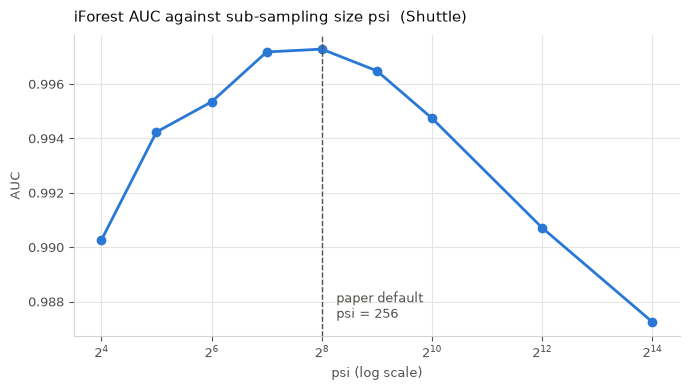

best psi here: 256 (AUC 0.9973);  at psi=16384: AUC 0.9873


In [22]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED   = "#0b0b0b", "#52514e"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, color=INK, fontsize=11, pad=10, loc="left")
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(True, color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#d4d3cf")
    ax.tick_params(colors=MUTED, labelsize=9)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(PSI_GRID, psi_auc, color=BLUE, linewidth=2, marker="o", markersize=6)
ax.set_xscale("log", base=2)
style(ax, "iForest AUC against sub-sampling size psi  (Shuttle)", "psi (log scale)", "AUC")
ax.axvline(PSI, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"paper default\npsi = {PSI}", xy=(PSI, min(psi_auc)), xytext=(PSI * 1.2, min(psi_auc)),
            color=MUTED, fontsize=9, va="bottom")
plt.tight_layout(); plt.show()

best = PSI_GRID[int(np.argmax(psi_auc))]
print(f"best psi here: {best} (AUC {max(psi_auc):.4f});  at psi={PSI_GRID[-1]}: AUC {psi_auc[-1]:.4f}")

**Reading the curve.** AUC does not keep improving with more data. It is highest for psi = 128, 256, 512 (0.9965–0.9973, differences within about one seed-to-seed sd) and then declines steadily, to 0.9873 at psi = 16,384. Larger samples make the detector slightly *worse*, which is the direction Section 3 predicts: with more points per tree, the members of the large anomaly class (class 5, Step 3) have more of their own kind around them in each sub-sample and need more splits to isolate (masking; Step 17 measures how close together they are). On Shuttle the effect is small — every psi tested stays far above ORCA and LOF — so here a small psi mainly saves time and memory at no cost in accuracy.

  t=   1  AUC 0.8949 +/- 0.0866
  t=   5  AUC 0.9900 +/- 0.0032
  t=  10  AUC 0.9924 +/- 0.0026
  t=  25  AUC 0.9962 +/- 0.0011
  t=  50  AUC 0.9973 +/- 0.0007
  t= 100  AUC 0.9973 +/- 0.0006
  t= 200  AUC 0.9972 +/- 0.0002


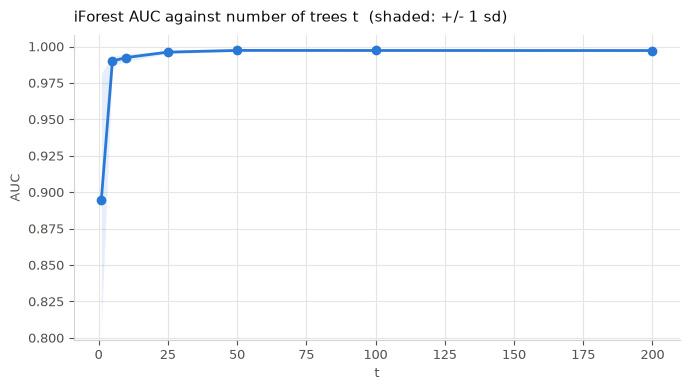

In [23]:
T_GRID = [1, 10, 50, 100] if FAST else [1, 5, 10, 25, 50, 100, 200]
t_auc, t_sd = [], []
for t_ in T_GRID:
    a = [roc_auc_score(y, IsolationForest(t_, PSI, seed=r).fit(X).score_samples(X))
         for r in range(SWEEP_RUNS)]
    t_auc.append(np.mean(a)); t_sd.append(np.std(a, ddof=1))
    print(f"  t={t_:4d}  AUC {np.mean(a):.4f} +/- {np.std(a, ddof=1):.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T_GRID, t_auc, color=BLUE, linewidth=2, marker="o", markersize=6)
ax.fill_between(T_GRID, np.array(t_auc) - np.array(t_sd), np.array(t_auc) + np.array(t_sd),
                color=BLUE, alpha=0.12, linewidth=0)
style(ax, "iForest AUC against number of trees t  (shaded: +/- 1 sd)", "t", "AUC")
plt.tight_layout(); plt.show()

AUC rises quickly with `t` (0.8949 with one tree, 0.9924 with 10) and changes little after about 50 trees (0.9973 at 50, 0.9973 at 100, 0.9972 at 200), while the spread across seeds shrinks. This matches Section 4.1 ("path lengths usually converge well before t = 100"): `t = 100` is a safe default rather than a tuned value.

Now ORCA's `k`. The paper raises this itself: for Http and Mulcross it reran ORCA with k = 150 and concluded that k-NN methods "can only detect low-density anomaly clusters of size smaller than k" (Section 5.1).

  k=    5  [0,1]-scaled 0.6250   raw 0.6975
  k=   10  [0,1]-scaled 0.6372   raw 0.7334
  k=   50  [0,1]-scaled 0.7011   raw 0.7837
  k=  150  [0,1]-scaled 0.7380   raw 0.8152
  k=  500  [0,1]-scaled 0.8371   raw 0.8637
  k= 1000  [0,1]-scaled 0.9086   raw 0.9582
  k= 3000  [0,1]-scaled 0.9847   raw 0.9939


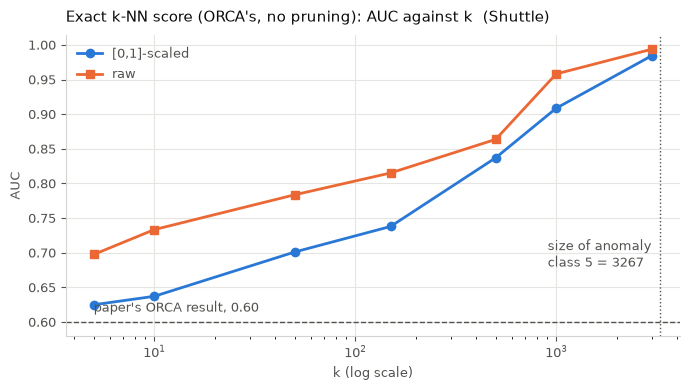

In [24]:
# the large-k entries dominate the runtime of the whole notebook !!
K_GRID = [5, 50, 500] if FAST else [5, 10, 50, 150, 500, 1000, 3000]
k_01, k_raw = [], []
for k_ in K_GRID:
    a_s = roc_auc_score(y, exact_knn_score(X01, k_))
    k_01.append(a_s)
    if FAST:
        print(f"  k={k_:5d}  [0,1]-scaled {a_s:.4f}")
    else:
        a_r = roc_auc_score(y, exact_knn_score(X, k_))
        k_raw.append(a_r)
        print(f"  k={k_:5d}  [0,1]-scaled {a_s:.4f}   raw {a_r:.4f}")

big = class_size[LARGEST_CLASS]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_GRID, k_01, color=BLUE, linewidth=2, marker="o", markersize=6, label="[0,1]-scaled")
if k_raw:
    ax.plot(K_GRID, k_raw, color=ORANGE, linewidth=2, marker="s", markersize=6, label="raw")
ax.set_xscale("log")
ax.axhline(PAPER["orca"], color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"paper's ORCA result, {PAPER['orca']:.2f}", xy=(K_GRID[0], PAPER["orca"]),
            xytext=(K_GRID[0], PAPER["orca"] + 0.015), color=MUTED, fontsize=9)
ax.axvline(big, color=MUTED, linewidth=1, linestyle=":")
ax.annotate(f"size of anomaly\nclass {LARGEST_CLASS} = {big}", xy=(big, 0.70), xytext=(big / 3.6, 0.68),
            color=MUTED, fontsize=9)
style(ax, "Exact k-NN score (ORCA's, no pruning): AUC against k  (Shuttle)", "k (log scale)", "AUC")
if k_raw:
    ax.legend(frameon=False, fontsize=9, labelcolor=MUTED)
if FAST:
    print("FAST: k stops at 500, so the climb past the largest anomaly class is not shown.")
plt.tight_layout(); plt.show()

The exact k-NN score climbs steadily as `k` grows: on [0,1]-scaled data from 0.6250 at k = 5 to 0.9086 at k = 1,000 and 0.9847 at k = 3,000, i.e. close to iForest only once `k` approaches the size of the largest anomaly class (dotted line, 3,267 points). This is the Section 5.1 remark seen on Shuttle; Step 17 looks at the mechanism.

Finally `N`, which controls how much ORCA prunes.

In [25]:
print("N controls pruning: smaller N -> more pruning -> less work, and fewer points get a score\n")
N_SETTINGS = ((8, "n/8 (paper)"), (1, "n (no pruning)")) if FAST else \
             ((8, "n/8 (paper)"), (4, "n/4"), (2, "n/2"), (1, "n (no pruning)"))
n_sweep = {}
for div, label in N_SETTINGS:
    N_ = max(1, len(X) // div)
    s_o, info = orca(X01, k=K_ORCA, N=N_, block=ORCA_BLOCK, seed=ORCA_SEEDS[0])
    n_sweep[label] = dict(N=N_, auc_topN=float(roc_auc_score(y, top_n_only(s_o, N_))),
                          pruned=info["pruned"],
                          dist_frac=info["distances_computed"] / info["distances_bruteforce"])
    r = n_sweep[label]
    print(f"  N = {label:15s} AUC top-N output {r['auc_topN']:.4f}   pruned {r['pruned']:6,}   "
          f"{100*r['dist_frac']:5.1f}% of the brute-force distances")

# with N = n, ORCA's scores should be the exact k-NN scores up to floating-point rounding
exact01 = exact_knn_score(X01, K_ORCA)
print(f"\n  N = n: max |ORCA score - exact score| = {np.abs(s_o - exact01).max():.1e};  "
      f"AUC {n_sweep['n (no pruning)']['auc_topN']:.4f} vs exact {roc_auc_score(y, exact01):.4f}")
print(f"  distinct exact scores among {len(X):,} points: {np.unique(exact01).size:,} "
      f"(the rest are ties, whose order rounding can flip)")

N controls pruning: smaller N -> more pruning -> less work, and fewer points get a score

  N = n/8 (paper)     AUC top-N output 0.5834   pruned 29,758    61.7% of the brute-force distances
  N = n/4             AUC top-N output 0.6027   pruned 19,322    77.9% of the brute-force distances
  N = n/2             AUC top-N output 0.6217   pruned  7,304    93.6% of the brute-force distances
  N = n (no pruning)  AUC top-N output 0.6252   pruned      0   100.0% of the brute-force distances

  N = n: max |ORCA score - exact score| = 2.1e-11;  AUC 0.6252 vs exact 0.6250
  distinct exact scores among 49,097 points: 25,729 (the rest are ties, whose order rounding can flip)


The smaller `N`, the more ORCA prunes, the less work it does — and the fewer points get a score, so the lower the AUC of its output: from 0.5834 at the paper's `N = n/8` to 0.6252 with `N = n`, where nothing is pruned. With `N = n`, ORCA's scores equal the exact k-NN scores up to floating-point rounding (largest difference 2.1e-11); the remaining AUC difference to the exact score (0.6250) comes from ties — only 25,729 of the 49,097 exact scores are distinct, and rounding can flip the order of tied points.

---
## Step 17 — Supplementary: why iForest wins here, measured

The headline is 0.9969 against 0.5834, but that is not a general verdict on the two methods. On this dataset it has a cause that can be measured rather than asserted.

Each method flags as many of its top-scored points as there are true anomalies (this uses the labels, so it is analysis after the fact, not part of either method), and we count how many members of each anomaly class are caught. The k-NN columns use ORCA's score computed exactly, so pruning plays no part. Then, for every class, the cell measures where its 5 nearest neighbours come from and how far away they are.

In [26]:
K_BIG = 5000            # [ours] a k larger than the largest anomaly class (checked below)
assert K_BIG > class_size[LARGEST_CLASS]
top = int(y.sum())

score_by_method = {f"iForest (psi={PSI})": IsolationForest(n_trees=T, subsample=PSI, seed=0)
                                               .fit(X).score_samples(X),
                   f"k-NN k={K_ORCA}": exact_knn_score(X01, K_ORCA)}
if not FAST:      # the K_BIG column is the single most expensive call in the notebook
    score_by_method[f"k-NN k={K_BIG}"] = exact_knn_score(X01, K_BIG)
flagged = {m: np.argsort(-s)[:top] for m, s in score_by_method.items()}

header = f"{'class':>6} {'size':>6}  " + "  ".join(f"{m:>18s}" for m in flagged)
print(f"recall per anomaly class, flagging the top {top} scores of each method\n")
print(header)
print("-" * len(header))
per_class = {}
for c in ANOMALY_CLASSES:
    members = np.flatnonzero(cls == c)
    recalls = {m: float(np.isin(members, idx).mean()) for m, idx in flagged.items()}
    per_class[c] = dict(size=int(members.size), recall=recalls)
    print(f"{c:6d} {members.size:6d}  " + "  ".join(f"{recalls[m]:18.3f}" for m in flagged))
auc_by_method = {m: float(roc_auc_score(y, s)) for m, s in score_by_method.items()}
print("-" * len(header))
print(f"{'AUC':>13s}  " + "  ".join(f"{auc_by_method[m]:18.4f}" for m in flagged))

# the mechanism, measured: who are each class's 5 nearest neighbours, and how far away are they?
_, nbr = NearestNeighbors(n_neighbors=K_ORCA + 1).fit(X01).kneighbors(X01)
nbr = nbr[:, 1:]                                   # drop column 0 (the point itself)
knn5 = score_by_method[f"k-NN k={K_ORCA}"]
print(f"\nneighbourhoods ([0,1]-scaled data, k = {K_ORCA})")
print(f"{'class':>6}  {'share of the 5 neighbours':>26s}  {'median 5-NN distance':>21s}")
print(f"{'':>6}  {'from the same class':>26s}")
neighbours = {}
for c in [1] + ANOMALY_CLASSES:
    members = np.flatnonzero(cls == c)
    same = float((cls[nbr[members]] == c).mean())
    med = float(np.median(knn5[members]))
    neighbours[c] = dict(same_class_share=same, median_knn5=med)
    print(f"{c:6d}  {same:26.3f}  {med:21.4f}" + ("   <- normal class" if c == 1 else ""))

recall per anomaly class, flagging the top 3511 scores of each method

 class   size   iForest (psi=256)            k-NN k=5         k-NN k=5000
-------------------------------------------------------------------------
     2     50               0.580               1.000               0.380
     3    171               0.784               1.000               0.316
     5   3267               0.976               0.129               1.000
     6     10               0.600               1.000               0.700
     7     13               0.538               1.000               0.462
-------------------------------------------------------------------------
          AUC              0.9976              0.6250              0.9901

neighbourhoods ([0,1]-scaled data, k = 5)
 class   share of the 5 neighbours   median 5-NN distance
               from the same class
     1                       1.000                 0.0001   <- normal class
     2                       0.888                 

**What the two tables say.**

With `k = 5` (ORCA's setting) the k-NN score catches every member of the four small classes (2, 3, 6, 7) but only 13% of class 5 — and class 5 holds 93% of all anomalies, so it decides the AUC.

The neighbourhood table shows why. 99.9% of the 5 nearest neighbours of a class-5 point are class-5 points themselves, and its median 5-NN distance (0.0002) is of the same order as that of normal points (0.0001), while the small classes sit much farther from their neighbours (median 0.0123–0.1576). A class-5 point is surrounded by its own kind, so with k = 5 it looks ordinary: this is masking, and it is the weakness the paper names in Section 5.1 — k-NN methods "can only detect low-density anomaly clusters of size smaller than k". The `k = 5000` column confirms the mechanism: with `k` larger than class 5, the class is caught completely (100%) and the AUC rises to 0.9901, close to iForest's — but small classes are lost instead (class 3: 32%), and choosing such a `k` requires knowing the cluster size in advance.

iForest needs no such knowledge: it catches 98% of class 5 with the default psi = 256, consistent with the argument of Section 3: a sub-sample of 256 points holds only about 17 class-5 points on average, so in every tree the cluster is thinned out. It is weaker than k = 5 on some small classes, which matters little for the AUC because they are few.

---
## Step 18 — Saving the results

Writes every measured number to a JSON file, so the report quotes the run instead of numbers typed by hand.

In [24]:
results = dict(
    environment=dict(python=sys.version.split()[0], numpy=np.__version__, sklearn=sklearn.__version__,
                     machine=f"{platform.platform()} | {platform.processor() or platform.machine()}",
                     threads=1),
    dataset=dict(n=int(X.shape[0]), d=int(X.shape[1]), anomalies=int(y.sum()),
                 anomaly_pct=float(100 * y.mean()), anomaly_classes=ANOMALY_CLASSES,
                 class_sizes=class_size, removed_class=int(REMOVED_CLASS)),
    settings=dict(t=T, psi=PSI, height_limit=int(math.ceil(math.log2(PSI))), attr_rule="all",
                  k_orca=K_ORCA, N_orca=int(N_ORCA), orca_block=ORCA_BLOCK, orca_seeds=ORCA_SEEDS,
                  orca_scaling="[0,1]", k_lof=K_LOF, lof_params={k: str(v) for k, v in LOF_PARAMS.items()},
                  n_runs=N_RUNS, sweep_runs=SWEEP_RUNS, k_big=K_BIG, fast=FAST),
    parameters=[dict(method=m, parameter=p, value=v, source=s) for m, p, v, s in params],
    figure1_demo=dict(xi_path=float(paths[i_xi]), xo_path=float(paths[i_xo]), xo_rank=rank_xo),
    iforest=dict(auc_mean=float(iforest_auc), auc_sd=float(iforest_sd),
                 train_s=float(iforest_train), eval_s=float(iforest_eval)),
    iforest_varying_rule=dict(auc_mean=var_auc, auc_sd=var_sd),
    sklearn=dict(auc_mean=sk_auc, auc_sd=sk_sd),
    empty_child_splits=dict(ours=[our_empty, our_splits], sklearn=[sk_empty, sk_splits]),
    orca=orca_results,
    lof=lof_results,
    comparison=comparison,
    times=[dict(item=name, ours_s=float(o), paper_s=p) for name, o, p in times],
    time_relative_to_iforest={m: dict(ours=float(o), paper=float(p)) for m, (o, p) in relative.items()},
    psi_sweep={int(p): [float(a), float(s)] for p, a, s in zip(PSI_GRID, psi_auc, psi_sd)},
    t_sweep={int(t_): [float(a), float(s)] for t_, a, s in zip(T_GRID, t_auc, t_sd)},
    orca_k_sweep={int(k_): dict(scaled01=float(a), **({"raw": float(b)} if k_raw else {}))
                  for k_, a, b in zip(K_GRID, k_01, k_raw or k_01)},
    orca_N_sweep=n_sweep,
    per_class=per_class,
    per_class_auc=auc_by_method,
    neighbourhoods=neighbours,
    paper=PAPER)

with open("results_shuttle_notebook.json", "w") as fh:
    json.dump(results, fh, indent=2)
print("saved results_shuttle_notebook.json")
print(json.dumps(results["iforest"], indent=2))
print(f"\ntotal notebook runtime: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

saved results_shuttle_notebook.json
{
  "auc_mean": 0.9969172464255873,
  "auc_sd": 0.0006228144520681339,
  "train_s": 0.1514582762,
  "eval_s": 0.8261464981
}

total notebook runtime: 17.3 min


---
## Summary of what was reproduced

All numbers are in the Step 14 tables and in `results_shuttle_notebook.json`, from one top-to-bottom run.

1. **The input is the paper's input.** The dataset was rebuilt from the original UCI files and checked by assertions against every property in Table 2. The class to remove was derived from Table 2, not assumed.
2. **iForest reproduces the paper.** Algorithms 1–3, implemented as written, give AUC 0.9969 ± 0.0006 (paper 1.00), in agreement with scikit-learn's independent implementation; the one open implementation detail changes the AUC by 0.0002.
3. **ORCA is close to the paper.** With its own preprocessing and its top-N output it gives 0.5834 (0.6025 on raw attributes) against 0.60. Exact k-NN scoring of every point gives more (0.6250), so the paper's value matches ORCA's actual output rather than the exact score. What remains depends on details the paper does not give.
4. **LOF reproduces the paper's 0.55** on raw attributes (0.5518).
5. **Timings differ in absolute terms** (hardware, implementations); iForest's speed advantage over ORCA carries over (23.1× here, 50.1× in the paper). LOF's time is not comparable.
6. **The iForest–ORCA gap on Shuttle has a measurable cause** (Step 17): most anomalies belong to one class whose members are each other's nearest neighbours, which hides them from a 5-nearest-neighbour score; iForest's small sub-samples do not have this problem.

**Decisions the paper leaves open**, each flagged [ours] where it is made and listed in Step 14: which class to remove and the pooling of the two files, derived from Table 2 (Step 3); fitting and scoring all n points, inferred from Sections 5.1 and 5.4 (Step 3); reading "randomly select" as uniform (Step 5); c(0) = 0 for empty leaves (Step 4); the treatment of points ORCA does not report (Step 10); scikit-learn's defaults for LOF (Step 13); seeds and numbers of repetitions. The details of ORCA that the iForest paper omits (score, [0,1] scaling, block size) were taken from ORCA's own paper, ref [3].